# Evaluate

Load a trained checkpoint and compare it with the simulator. Nothing here trains; checkpoints come
from `notebooks/train.ipynb`.

Sections:

1. **Training summary**: what the checkpoint was trained on, and its loss curves.
2. **Predictions**: the model next to the simulator on random validation pairs.
3. **Animation**: one run eroded by the model and by the simulator, as a GIF.
4. **Accuracy**: height error, rivers, fine detail, where the model fails, and chained calls.
5. **Speed**: time per model call against the simulator.
6. **Variable elapsed time**: for a model trained on many elapsed times (`variable_dt`): random start
   and elapsed times, error against elapsed time, and an animation with one model call per frame.

In [1]:
from IPython.display import Image as ShowImage

from erosion_sim.data import ARTIFACTS_DIR, dataset_dir, load_params, select_runs
from erosion_sim.evaluate import (error_by_condition, error_by_elapsed, error_metrics, hydrology_metrics, predict_pairs,
                                  rollout_error, show_predictions, spectrum_comparison, speed_comparison)
from erosion_sim.generate import comparison_gif
from erosion_sim.train import load_checkpoint, plot_history

print("saved checkpoints:")
for path in sorted(ARTIFACTS_DIR.glob("unet-*.pt")):
    print(" ", path.name)

saved checkpoints:
  unet-fixed_dt.pt
  unet-overfit.pt


## 1. Training summary

profile fixed_dt: saved at step 19000 of 20000, best validation skill 0.990
runs: {'U': (0.0, 0.0)}
elapsed times (snapshot steps of 1,000 yr): (10,)
target scaling: fitted, 0.0345 * (K_ref * dT) ** 0.896


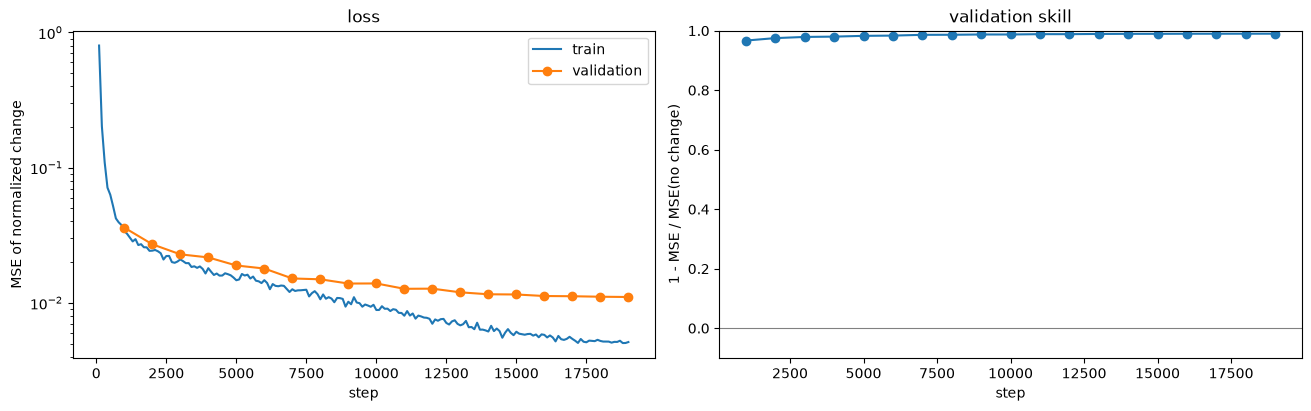

In [2]:
CHECKPOINT = ARTIFACTS_DIR / "unet-variable_dt.pt"

model, normalizer, cfg, ckpt = load_checkpoint(CHECKPOINT)
history = ckpt["history"]
print(f"profile {cfg.profile}: saved at step {ckpt['step']} of {cfg.steps}, "
      f"best validation skill {max(history['val_skill']):.3f}")
print(f"runs: {dict(cfg.runs) or 'all'}")
print(f"elapsed times (snapshot steps of 1,000 yr): {cfg.lags if cfg.lags is not None else 'all'}")
print(f"target scaling: {normalizer.scale}, {normalizer.coef:.4f} * (K_ref * dT) ** {normalizer.power:.3f}")
plot_history(history)

## 2. Predictions

Each row is one random validation pair from runs that match the checkpoint's run filter. A pair can
start at any snapshot of its run; only the gap between start and end is fixed by the profile.
Columns: start, simulator end, model end, simulator change, model change, and the error.

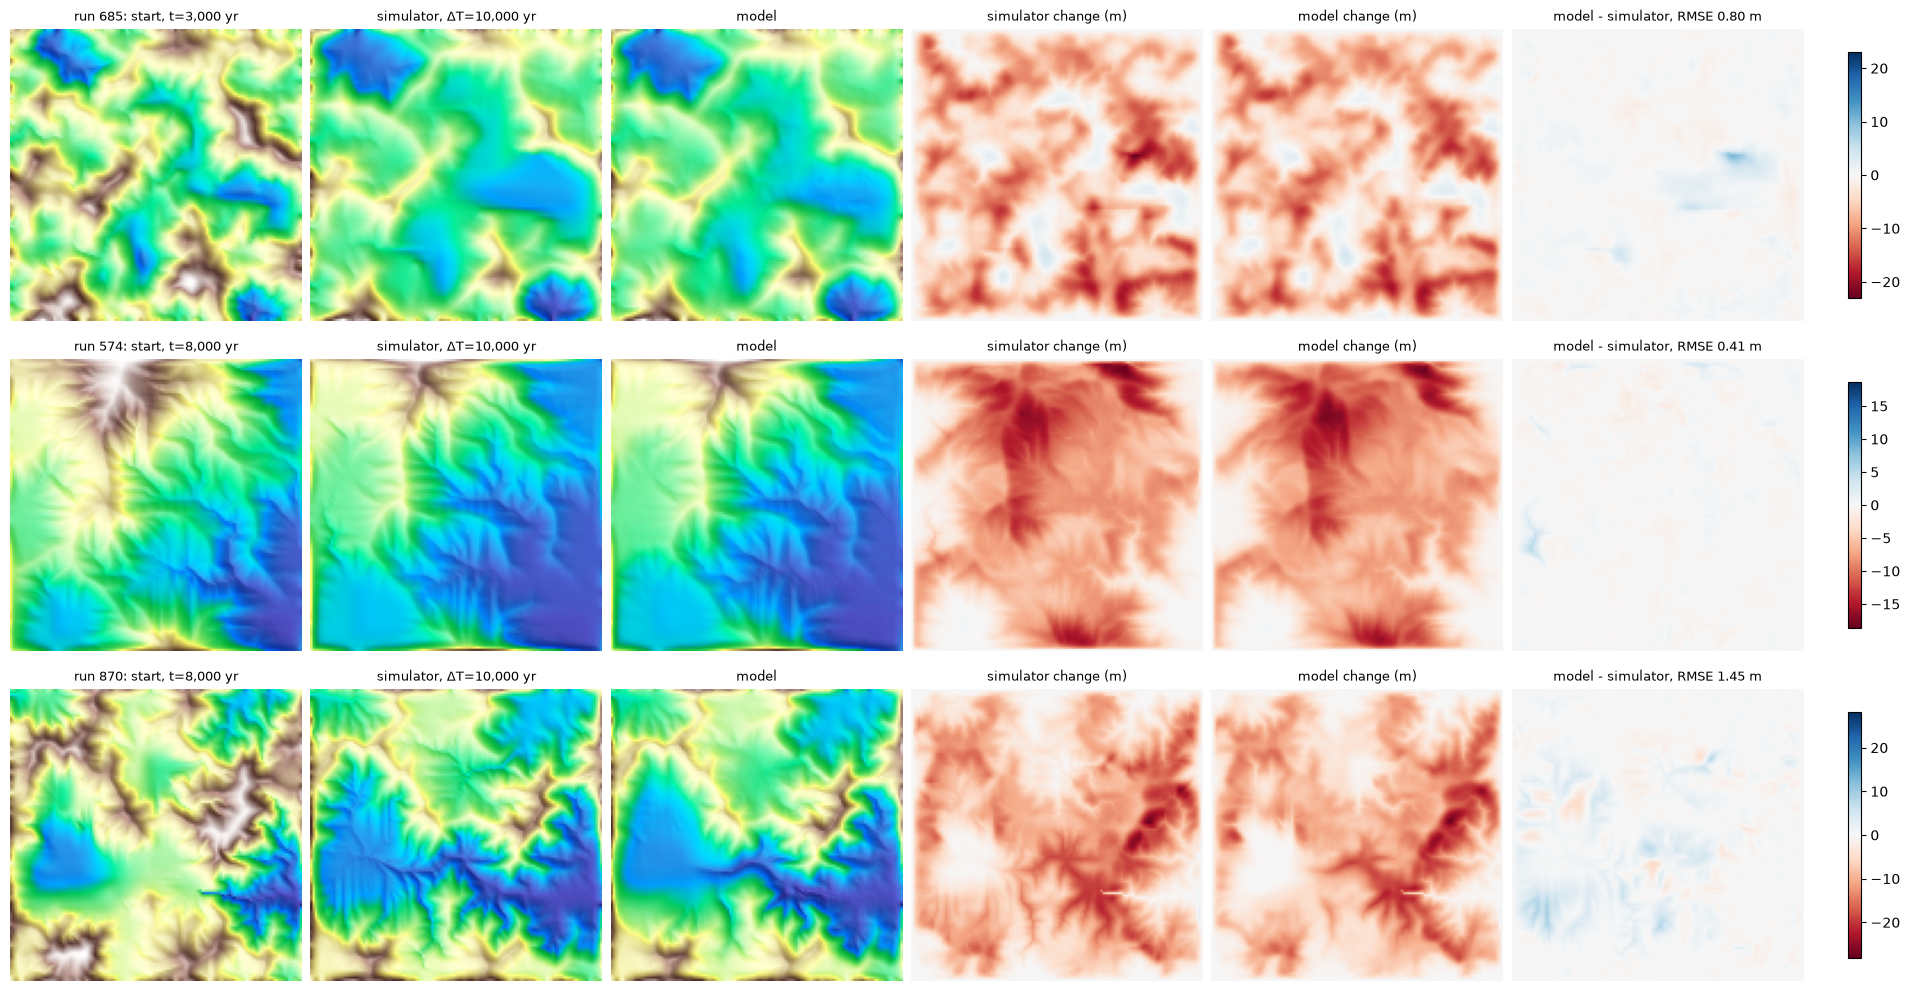

In [3]:
show_predictions(CHECKPOINT, count=3, seed=0)

## 3. Animation: simulator against model

Erodes one run with the model, starting from the simulator's snapshot at t = 0, and animates it next
to the simulator. Top row 2D, bottom row 3D with rivers in blue; both share one color scale and camera.
The GIF is saved to `artifacts/animations/`.

- `MODE = "rollout"` feeds each prediction back in as the next start, `LAG` snapshots at a time. A
  model trained on one elapsed time (`fixed_dt`) can only be used this way, and errors add up.
- `MODE = "direct"` predicts every frame straight from t = 0. Only meaningful for a model trained on
  many elapsed times (`variable_dt`).
- `LAG = None` uses the model's training elapsed time if it has one, else 1 snapshot (1,000 yr).

`INDEX` picks from the split's runs that match the checkpoint's run filter (for example, no uplift).

In [4]:
SPLIT = "val"
INDEX = 0
MODE = "rollout"
LAG = None
FPS = 2

params, _ = load_params(dataset_dir(cfg.data_profile, SPLIT))
matching = select_runs(params, **dict(cfg.runs))
RUN = int(matching[INDEX])
print(f"{len(matching)} matching {SPLIT} runs; showing run {RUN}")

gif = comparison_gif(CHECKPOINT, run=RUN, split=SPLIT, lag=LAG, mode=MODE, fps=FPS)
print(f"saved {gif}")
ShowImage(filename=gif)

333 matching val runs; showing run 0


saved /home/jay/Work/repos/erosion-sim-modeling/artifacts/animations/unet-fixed_dt-val-run0-rollout.gif


## 4. Accuracy

The model is compared with the simulator, in meters. **No change** (the end terrain equals the start)
is shown as a reference row: skill is defined against it, and it shows what the river numbers mean.

The cell below runs the model once on `COUNT` random validation pairs (from runs
matching the checkpoint's run filter, at its training elapsed times). The cells after it reuse them.

In [5]:
COUNT = 2048  # about 1 minute with the river metrics
pairs = predict_pairs(CHECKPOINT, split="val", count=COUNT, seed=0)

### 4.1 Height error

- **RMSE**: root mean squared error of the end heightmap, in m.
- **Skill**: `1 - MSE / MSE(no change)`, where MSE is mean squared error. The fraction of the
  simulator's change the method gets right, in squared terms. 0 is no better than doing nothing, 1 is
  perfect, below 0 is worse than doing nothing. Over all pairs together, and the median per pair.
- **Erosion ratio**: how much the method changes the terrain over how much the simulator does.
  1 is right; below 1 is too little.

In [6]:
errors = error_metrics(pairs)

512 pairs; simulator's mean absolute change 3.518 m

          method  RMSE (m)   skill  median skill  erosion ratio
       no change     4.908   0.000         0.000          0.000
           model     0.488   0.990         0.994          0.998


### 4.2 Rivers

Water is routed over each end heightmap (D8: each cell drains to its steepest downhill neighbor, no pit
filling). Channels are cells whose drainage area is at least the simulator's 95% quantile.

- **Channel IoU**: intersection over union of the method's channel cells and the simulator's. 1 is a
  perfect match. A channel one cell off counts as a miss.
- **IoU, 1 cell**: the same after widening both channel masks by one cell, so small shifts still match.
- **log10 area RMSE**: error in drainage area, on a log scale, over every cell.
- **Pits**: interior cells with no lower neighbor. Water stops at a pit, so pits break rivers. The
  simulator's terrain has a few too; compare with its count.

No change is a real baseline here: most of the start terrain's rivers survive.
The plot shows the channels of one pair.

channel threshold: drainage area >= 98 cells (simulator's 95% quantile)
simulator: 5.6 pits per terrain

          method  channel IoU  IoU, 1 cell  log10 area RMSE    pits
       no change        0.492        0.668            0.469    10.0
           model        0.460        0.642            0.447    59.2


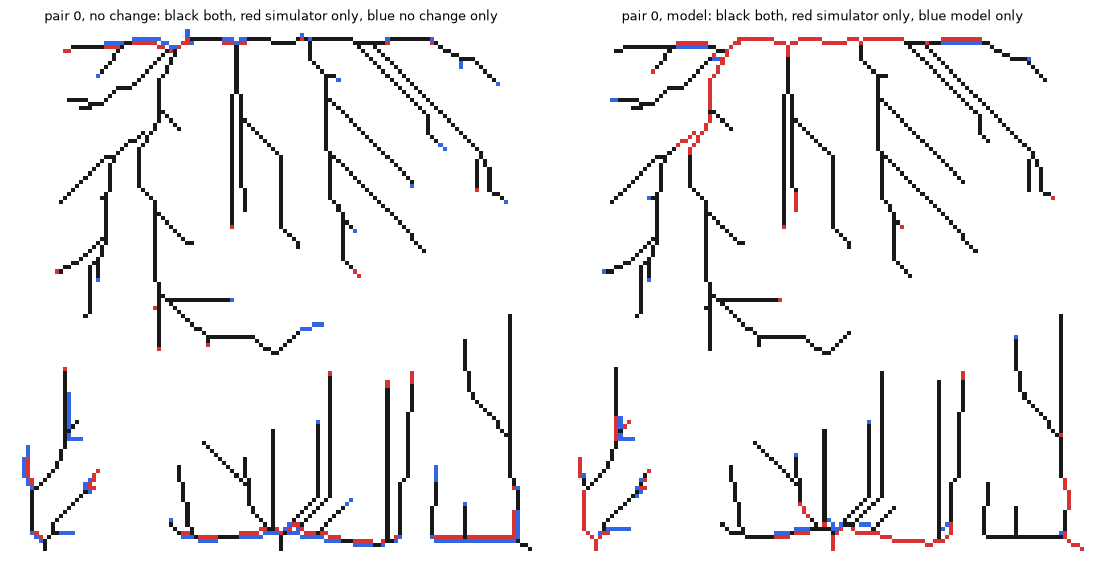

In [7]:
hydro = hydrology_metrics(pairs, example=0)

### 4.3 Fine detail

Power spectrum of the change (end minus start): how much of the change happens at each scale,
averaged over pairs. Right is fine detail. On the right panel, 1 means the model matches the
simulator at that scale; below 1 means detail is smoothed away.

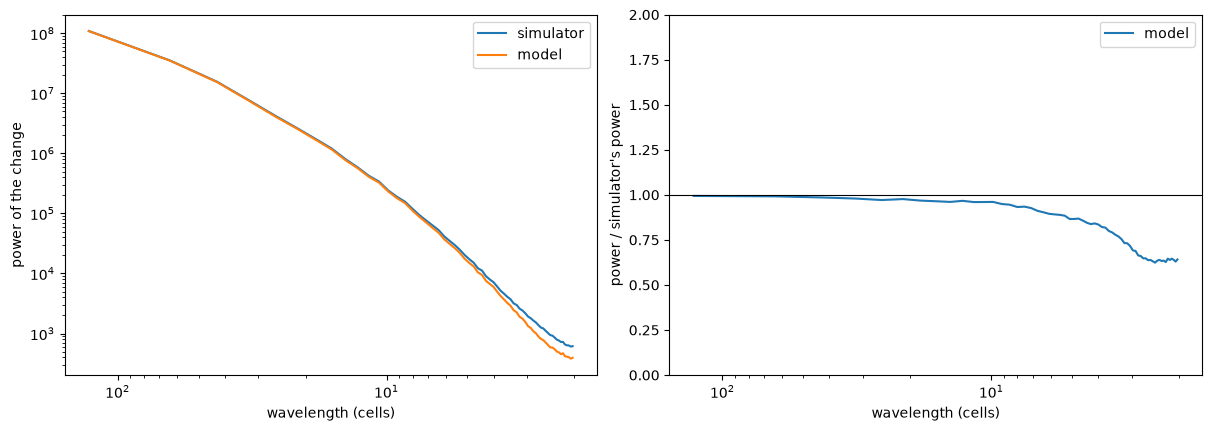

In [8]:
spectrum = spectrum_comparison(pairs)

### 4.4 Where the model fails

Skill per pair against each parameter, the start time, and the elapsed time. Dots are pairs; lines
are medians in bins with equal numbers of pairs. Parameters with one value in the sample (for example
uplift for `fixed_dt`) are skipped.

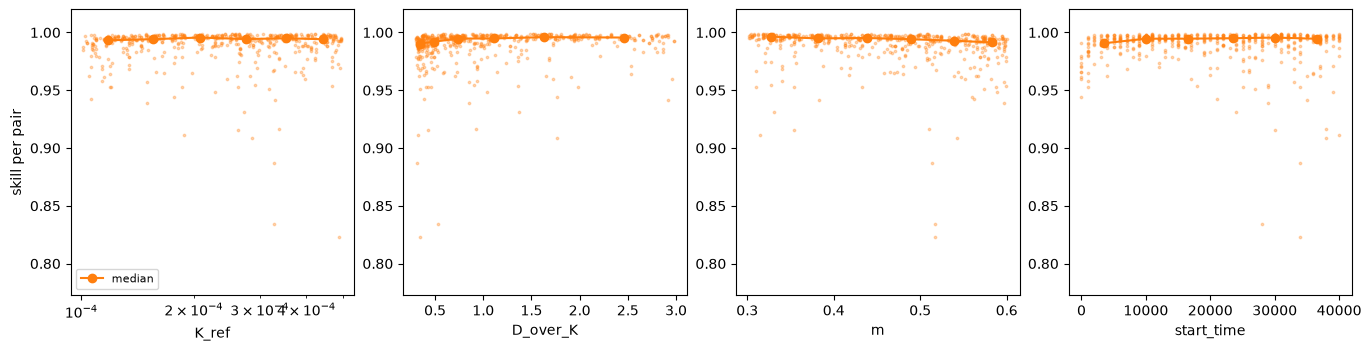

In [9]:
by_condition = error_by_condition(pairs)

### 4.5 Chained calls

Error against elapsed time from t = 0, over `RUNS` validation runs.

- **rollout**: each model call starts from the model's previous output.
- **one call**: one model call from the simulator's terrain one step earlier. The gap between this and
  rollout is the error added by chaining.
- **direct**: one model call from t = 0 straight to each time. Shown only for a model trained on every
  one of those elapsed times (`variable_dt`).
- **no change**: the terrain at t = 0.

Skill here is against no change from t = 0.

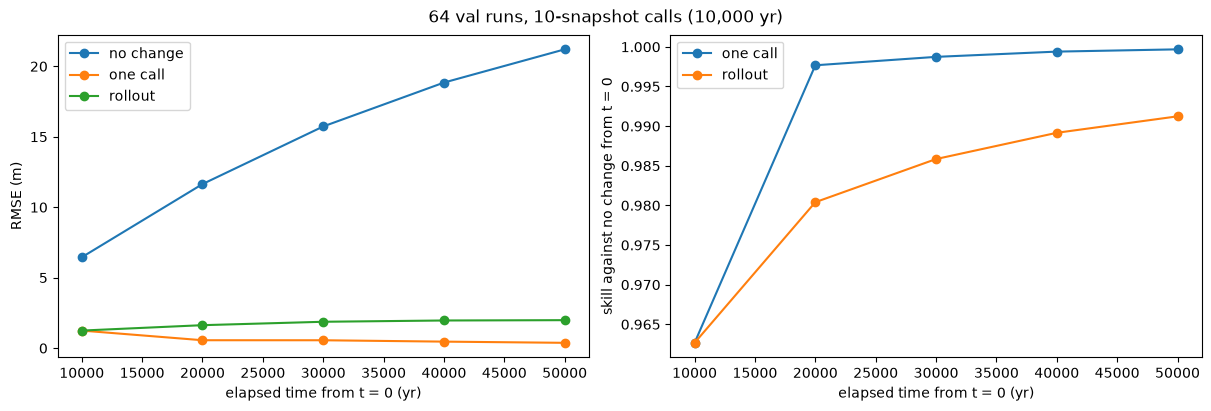

In [10]:
RUNS = 64
chained = rollout_error(CHECKPOINT, split="val", runs=RUNS)

## 5. Speed

Time to erode one 128×128 terrain by each elapsed time.

- **Simulator**: timed now, on one CPU core, on the same run's parameters, in the `datagen`
  environment. Its cost grows with the elapsed time: one 100-yr step at a time.
- **Model**: one call per elapsed time it was trained on. To cover a longer time, calls are chained
  (rollout), so the cost is the number of calls times one call. If no combination of its trained
  elapsed times adds up exactly, the model cannot produce that time: `fixed_dt` only does multiples of
  10,000 yr.
- Model times are shown on the CPU, on the GPU, and per terrain when 64 terrains go through the GPU
  together.

In [11]:
speed = speed_comparison(CHECKPOINT, split="val", run=RUN)

simulator: 3.78 ms per 100-yr step, one CPU core
model: 26.1 ms per call on CPU, 2.6 ms on GPU, 1.67 ms per terrain in batches of 64
model trained on elapsed times (yr): [10000]

  elapsed time    simulator  model calls   model, CPU   model, GPU  GPU, batched
      1,000 yr      37.8 ms not possible            -            -             -
     10,000 yr     378.1 ms            1      26.1 ms       2.6 ms        1.7 ms
     25,000 yr     945.1 ms not possible            -            -             -
     50,000 yr    1890.3 ms            5     130.6 ms      12.9 ms        8.4 ms


## 6. Variable elapsed time

For a model trained on many elapsed times (`variable_dt`). Every pair here is from the validation split:
runs (terrains and parameters) the model never trained on, from the same distribution. The test split
stays untouched for final numbers.

### 6.1 Random start and elapsed times

Each row is a random validation pair: a random run, start snapshot, and elapsed time. Columns as in
section 2. Change `SEED` for another draw.

In [ ]:
SEED = 1
show_predictions(CHECKPOINT, count=6, seed=SEED)

### 6.2 Error against elapsed time

Uses the pairs from section 4, grouped by elapsed time into bins with equal numbers of pairs.

- **RMSE**: in m. Grows with elapsed time, because the change itself grows.
- **Skill**: against no change, for the pairs in each bin. Flat means the model is equally good,
  relative to the size of the change, at every elapsed time.
- **Channel IoU**: as in section 4.2. No change is the line to beat: its rivers are the start's.
- **Grid**: median skill per pair, by start time and elapsed time. The empty corner is end times past
  the last snapshot (50,000 yr).

In [ ]:
by_elapsed = error_by_elapsed(pairs)

### 6.3 Animation with one model call per frame

Like section 3, but every frame is its own model call straight from the simulator's terrain at t = 0
(`MODE = "direct"`): frame k asks the model to erode the t = 0 terrain for k × `LAG` snapshots. No
output is fed back in, so errors cannot add up from frame to frame. `LAG = 1` gives 51 frames, 1,000 yr
apart; about 20 seconds.

In [ ]:
INDEX = 0
LAG = 1
FPS = 6

params, _ = load_params(dataset_dir(cfg.data_profile, "val"))
matching = select_runs(params, **dict(cfg.runs))
RUN = int(matching[INDEX])
print(f"{len(matching)} matching val runs; showing run {RUN}")

gif = comparison_gif(CHECKPOINT, run=RUN, split="val", lag=LAG, mode="direct", fps=FPS)
print(f"saved {gif}")
ShowImage(filename=gif)